# Telco Customer Churn Prediction

A reproducible binary-classification workflow for predicting telecom customer churn.

**Models:** Logistic Regression baseline, untuned XGBoost, and Optuna-tuned XGBoost.  
**Evaluation:** stratified hold-out test set, cross-validation on training data, ROC-AUC, precision, recall, F1, PR-AUC, confusion matrices, and ROC/precision-recall curves.  
**Explainability:** SHAP global feature importance.

> Methodology note: all preprocessing is fitted inside scikit-learn pipelines. Hyperparameter selection uses training data only. The hold-out test set is evaluated once, after all model choices are finalized.

## 1. Setup

In [2]:
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import optuna
#import shap

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
CHART_DIR = "outputs/charts"
os.makedirs(CHART_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Load and inspect data

In [3]:
df = pd.read_csv("telco_churn.csv")

# customerID is an identifier, not a predictive feature.
df = df.drop(columns=["customerID"])

# TotalCharges contains blank strings in the source dataset.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype("int64")

print("Dataset shape:", df.shape)
display(df.head())
display(df["Churn"].value_counts(normalize=True).rename("proportion"))
display(df.isna().sum().sort_values(ascending=False).head())

Dataset shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

TotalCharges      11
gender             0
SeniorCitizen      0
MonthlyCharges     0
PaymentMethod      0
dtype: int64

## 3. Exploratory data analysis

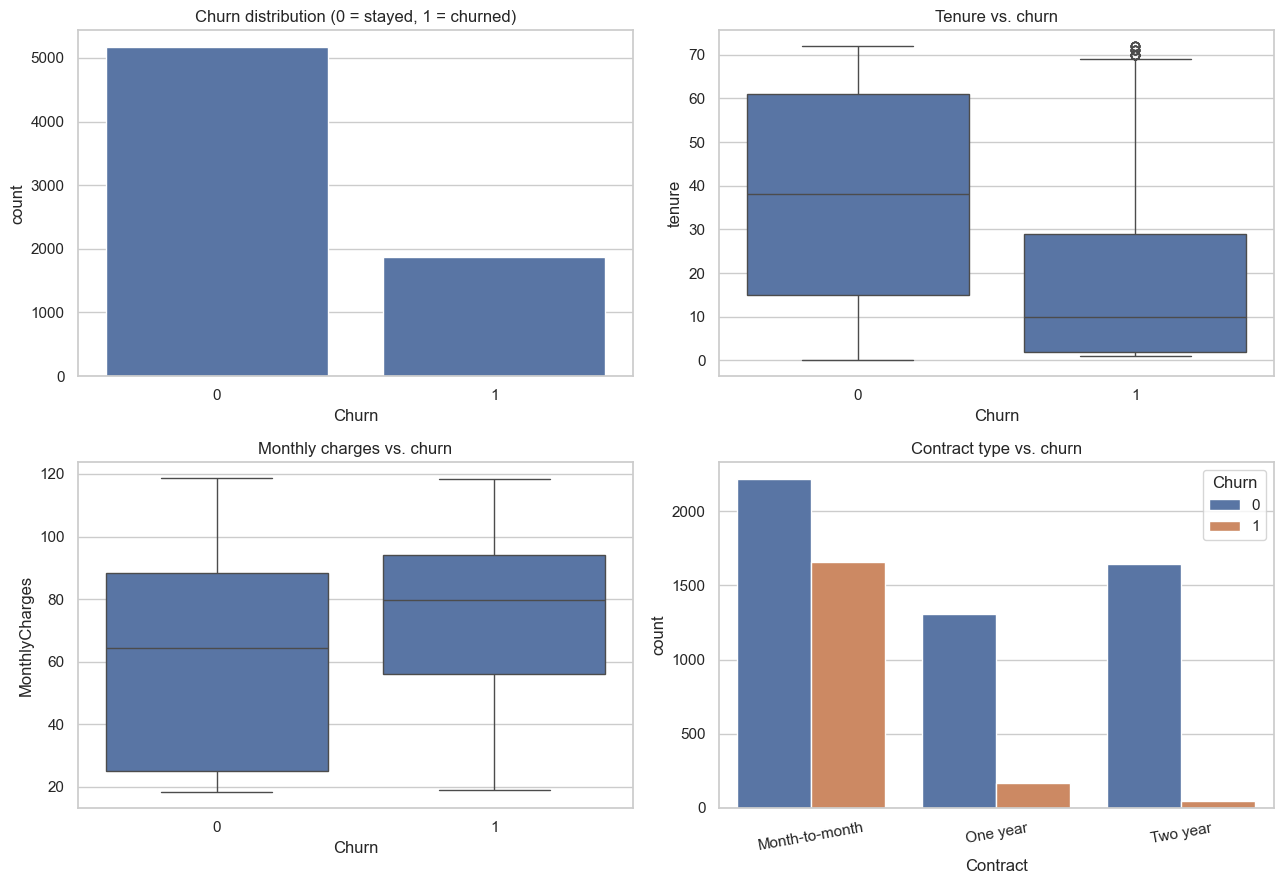

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn distribution (0 = stayed, 1 = churned)")
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0, 1])
axes[0, 1].set_title("Tenure vs. churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1, 0])
axes[1, 0].set_title("Monthly charges vs. churn")
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[1, 1])
axes[1, 1].set_title("Contract type vs. churn")
axes[1, 1].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/01_eda_overview.png", dpi=160, bbox_inches="tight")
plt.show()

**Initial observations:** the target is imbalanced, and exploratory plots can reveal associations between churn and customer tenure, charges, and contract type. These are descriptive associations, not proof of causation.

## 4. Split before fitting preprocessing

In [5]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")

Training rows: 5,634; test rows: 1,409
Numeric features: 4
Categorical features: 15


## 5. Preprocessing and baseline model

The preprocessing steps are part of each pipeline. This prevents the imputer, scaler, or encoder from learning from validation/test rows. Numeric missing values are median-imputed; categorical missing values are most-frequent-imputed; categorical variables are one-hot encoded.

In [6]:
numeric_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocess_lr = ColumnTransformer(transformers=[
    ("num", numeric_lr, numeric_features),
    ("cat", categorical_preprocess, categorical_features)
])

# XGBoost does not require feature scaling.
numeric_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
preprocess_tree = ColumnTransformer(transformers=[
    ("num", numeric_tree, numeric_features),
    ("cat", categorical_preprocess, categorical_features)
])

logreg_pipeline = Pipeline(steps=[
    ("preprocess", preprocess_lr),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
logreg_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])

## 6. XGBoost baseline and class imbalance

In [7]:
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_baseline_pipeline = Pipeline(steps=[
    ("preprocess", preprocess_tree),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=positive_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])
xgb_baseline_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=1,
                               num_parallel_tree=None, random_state=42, ...))])

## 7. Hyperparameter tuning with Optuna

Five-fold stratified cross-validation is performed on the training set only. Each fold fits its own preprocessing pipeline. ROC-AUC is used as the optimization objective; other metrics are reported later because model selection should be tied to an explicitly chosen objective.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 150, 700),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 8),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
    }
    candidate = Pipeline(steps=[
        ("preprocess", preprocess_tree),
        ("model", XGBClassifier(
            **params,
            scale_pos_weight=positive_weight,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ])
    scores = cross_val_score(
        candidate, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    return scores.mean()

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=50)

print("Best training CV ROC-AUC:", round(study.best_value, 4))
print("Best parameters:", study.best_params)

[I 2026-11-03 11:19:46,547] A new study created in memory with name: no-name-8de21558-c68d-40dc-a1d7-f318865d2069
[I 2026-11-03 11:19:50,357] Trial 0 finished with value: 0.8180942068742851 and parameters: {'n_estimators': 356, 'max_depth': 8, 'learning_rate': 0.08960785365368121, 'subsample': 0.8595304694689628, 'colsample_bytree': 0.7046065241548528, 'min_child_weight': 2, 'reg_lambda': 0.014936568554617643}. Best is trial 0 with value: 0.8180942068742851.
[I 2026-11-03 11:19:53,186] Trial 1 finished with value: 0.8139545334420907 and parameters: {'n_estimators': 627, 'max_depth': 6, 'learning_rate': 0.08341106432362087, 'subsample': 0.6572045730035309, 'colsample_bytree': 0.989468448256698, 'min_child_weight': 7, 'reg_lambda': 0.04335281794951567}. Best is trial 0 with value: 0.8180942068742851.
[I 2026-11-03 11:19:55,341] Trial 2 finished with value: 0.8497270985533387 and parameters: {'n_estimators': 250, 'max_depth': 3, 'learning_rate': 0.024878734419814436, 'subsample': 0.833664

Best training CV ROC-AUC: 0.8507
Best parameters: {'n_estimators': 535, 'max_depth': 2, 'learning_rate': 0.015456858102705074, 'subsample': 0.6528539011219889, 'colsample_bytree': 0.8925066259678235, 'min_child_weight': 4, 'reg_lambda': 0.049371826302497805}


## 8. Fit final candidate models

In [9]:
xgb_tuned_pipeline = Pipeline(steps=[
    ("preprocess", preprocess_tree),
    ("model", XGBClassifier(
        **study.best_params,
        scale_pos_weight=positive_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])
xgb_tuned_pipeline.fit(X_train, y_train)

# All model choices are now finalized. The test set is evaluated below once.

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               learning_rate=0.015456858102705074, max_bin=None,
                               max_cat_threshold=None, max_cat_to_onehot=None,
                               max_delta_step=None, max_depth=2,
                               max_leaves=None, min_child_weight=4, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=535, n_jobs=1,
                               num_parallel_tree=None, random_state=42, ...))])

## 9. Final hold-out evaluation

The following is the only section that evaluates the hold-out test set. Do not use these results to change hyperparameters or select another model; doing so would turn the test set into validation data.

In [10]:
models = {
    "Logistic Regression": logreg_pipeline,
    "XGBoost baseline": xgb_baseline_pipeline,
    "XGBoost tuned": xgb_tuned_pipeline,
}

test_probabilities = {}
test_predictions = {}
rows = []

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    test_probabilities[name] = probabilities
    test_predictions[name] = predictions
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC (average precision)": average_precision_score(y_test, probabilities),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results.round(3))

for name, predictions in test_predictions.items():
    print(f"\n{name}")
    print(classification_report(
        y_test, predictions, target_names=["Stayed", "Churned"], zero_division=0
    ))
    print("Confusion matrix (rows=actual, columns=predicted):")
    print(confusion_matrix(y_test, predictions))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (average precision)
Model,,,,,,
XGBoost tuned,0.743,0.510,0.805,0.624,0.846,0.664
Logistic Regression,0.806,0.657,0.559,0.604,0.842,0.633
XGBoost baseline,0.755,0.526,0.773,0.626,0.840,0.653



Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion matrix (rows=actual, columns=predicted):
[[926 109]
 [165 209]]

XGBoost baseline
              precision    recall  f1-score   support

      Stayed       0.90      0.75      0.82      1035
     Churned       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409

Confusion matrix (rows=actual, columns=predicted):
[[775 260]
 [ 85 289]]

XGBoost tuned
              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80      1035
     Churned       0.51      0.80  

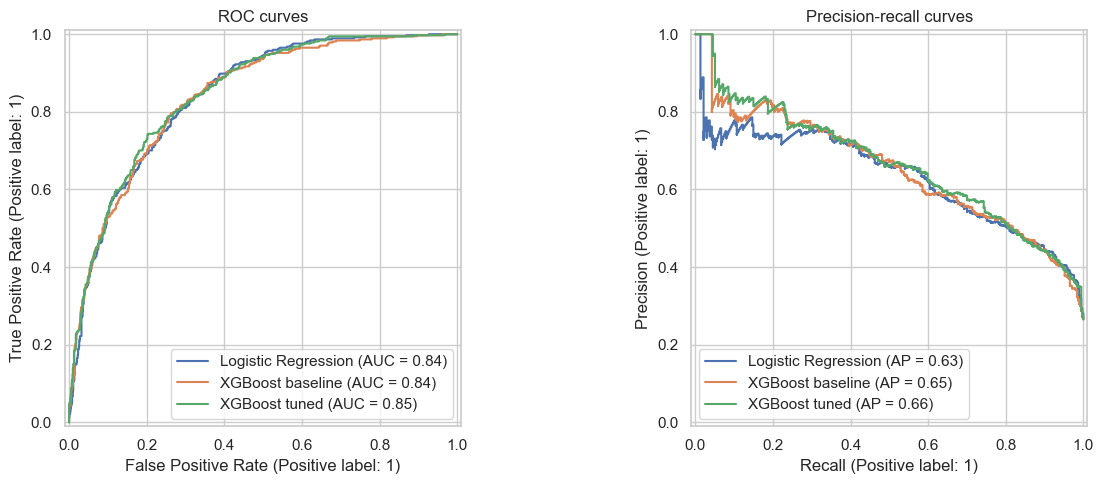

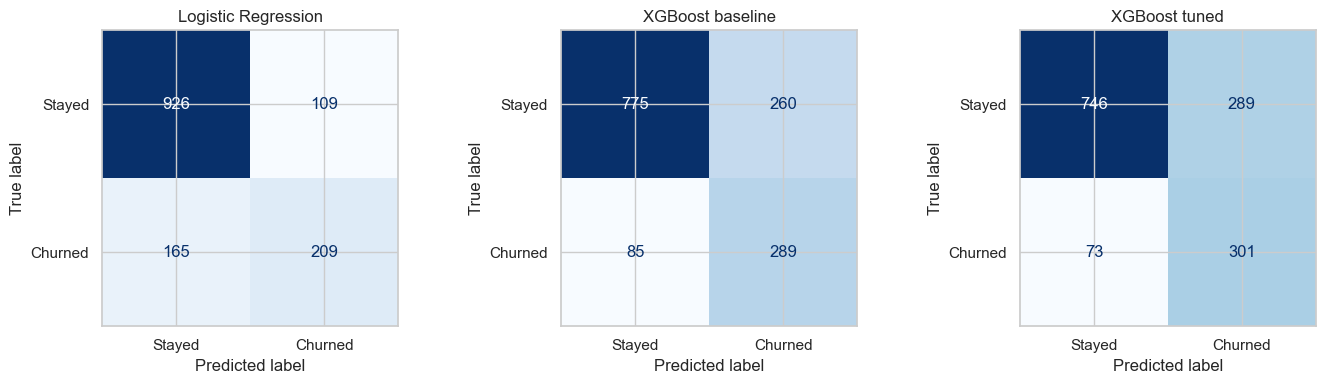

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[1])
axes[0].set_title("ROC curves")
axes[1].set_title("Precision-recall curves")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/02_model_curves.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, predictions) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, display_labels=["Stayed", "Churned"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/03_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()